Task 1

In [2]:
import requests
import pandas as pd
import matplotlib.pyplot as plt 
import frost_met_code as fmc


# Source: Norwegian Meteorological Institute(Frost API)

# Insert your own client ID here
client_id = fmc.client_credentials

# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
json = r.json()



# Check if the request worked, print out any errors
if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])



# This will return a Dataframe with all of the observations in a table format
rows = []

for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    rows.append(row)

df = pd.concat(rows, ignore_index=True)

df.head()


df["date"] = pd.to_datetime(df["referenceTime"])

plt.figure(figsize=(12, 5))
plt.plot(
    df["date"], 
    df["value"], 
    color="tab:red", 
    label="temperature")
months = pd.date_range(start="2025-01-01", end="2025-12-01", freq="MS")
month_names = ["Jan", "Feb", "Mar", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Des"]
plt.xticks(ticks=months, labels=month_names)
plt.title("Temperature during the day in Ås (2025)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Summary table

summary_df = pd.DataFrame({
    "Metrikk": ["Mean", "Median", "Minimum", "Maximum"],
    "Temperature (°C)": [
        df["value"].mean(),
        df["value"].median(),
        df["value"].min(),
        df["value"].max()
    ]
})

print("Summary table for 2025")
print(summary_df.to_string(index=False))

ModuleNotFoundError: No module named 'requests'

Task 2

In [ ]:

endpoint_prec = 'https://frost.met.no/observations/v0.jsonld'
parameters_prec = {
    'sources': 'SN17850',
    'elements': 'sum(precipitation_amount P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r_prec = requests.get(endpoint_prec, parameters_prec, auth=(client_id,''))
json_prec = r_prec.json()
data_precip = json_prec["data"]  # Endret til data_precip her

rows_precip = []

for i in range(len(data_precip)):
    row = pd.DataFrame(data_precip[i]['observations'])
    row['referenceTime'] = data_precip[i]['referenceTime']
    row['sourceId'] = data_precip[i]['sourceId']
    rows_precip.append(row)

df_precip = pd.concat(rows_precip, ignore_index=True)

# Converting time
df_precip["date"] = pd.to_datetime(df_precip["referenceTime"])
df_precip.head()

# makin 2 y-axis
fig, plt_1 = plt.subplots(figsize=(12, 5))

# Temperature
plt_1.plot(df["date"], df["value"], color="tab:red", label="temperature (2025)")
plt_1.set_xlabel("Date")
plt_1.set_ylabel("Temperature (°C)", color="tab:red")
plt_1.set_xticks(months)
plt_1.set_xticklabels(month_names)
plt_1.grid(True, linestyle="--", alpha=0.6)

# Precipitation
plt_2 = plt_1.twinx()
plt_2.bar(df_precip["date"], df_precip["value"], color="tab:blue", alpha=0.4, label="precipitation (2025)")
plt_2.set_ylabel("Precipitation (mm)", color="tab:blue")

plt.title("temperature and precipitation in Ås 2025")
plt.tight_layout()
plt.show()


# Summary table
summary_precip = pd.DataFrame({
    "Metrikk": ["Mean", "Median", "Minimum", "Maximum"],
    "Precipitation (mm)": [
        df_precip["value"].mean(), 
        df_precip["value"].median(),
        df_precip["value"].min(),
        df_precip["value"].max()
    ]
})

print("Summary table for precipitation (2025)")
print(summary_precip.to_string(index=False))

NameError: name 'requests' is not defined

Task 3

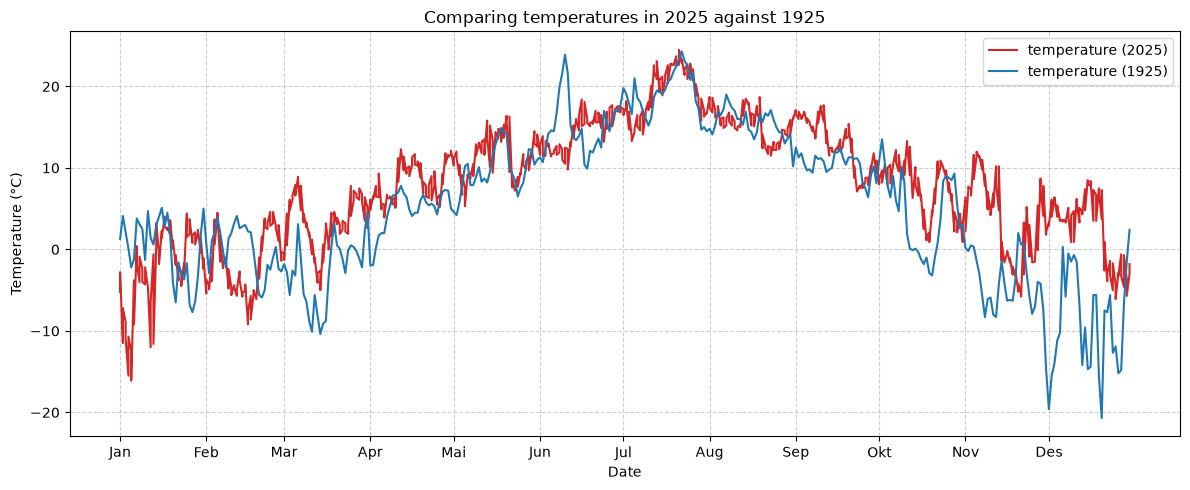

Summary table for 2025
Metrikk  Temperature (°C)
   Mean          7.903571
 Median          8.350000
Minimum        -16.100000
Maximum         24.500000

Summary table for 1925
Metrikk  Temperature (°C)
   Mean           5.31044
 Median           5.30000
Minimum         -20.70000
Maximum          24.30000


In [ ]:

endpoint_1925 = 'https://frost.met.no/observations/v0.jsonld'
parameters_1925 = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '1925-01-01/1925-12-31',
}

# Issue an HTTP GET request
r_1925 = requests.get(endpoint_1925, parameters_1925, auth=(client_id,''))
# Extract JSON data
json_1925 = r_1925.json()
data_1925 = json_1925["data"]


rows_1925 = []

for i in range(len(data_1925)):
    row = pd.DataFrame(data_1925[i]['observations'])
    row['referenceTime'] = data_1925[i]['referenceTime']
    row['sourceId'] = data_1925[i]['sourceId']
    rows_1925.append(row)

df_1925 = pd.concat(rows_1925, ignore_index=True)

df_1925.head()
 
df_1925["date"] = pd.to_datetime(df_1925["referenceTime"])



x_2025 = df["date"]
x_1925 = df_1925["date"].apply(lambda d: d.replace(year=2025))


plt.figure(figsize=(12, 5))
plt.plot(
    x_2025, df["value"], color="tab:red", label="temperature (2025)"
)
plt.plot(
    x_1925, df_1925["value"], 
    color="tab:blue", label="temperature (1925)"
)
plt.xticks(ticks=months, labels=month_names)
plt.title("Comparing temperatures in 2025 against 1925")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


# Summary table

summary_df_1925 = pd.DataFrame({
    "Metrikk": ["Mean", "Median", "Minimum", "Maximum"],
    "Temperature (°C)": [
        df_1925["value"].mean(),
        df_1925["value"].median(),
        df_1925["value"].min(),
        df_1925["value"].max()
    ]
})

print("Summary table for 2025")
print(summary_df.to_string(index=False))

print("\nSummary table for 1925")
print(summary_df_1925.to_string(index=False))



Task 4

Task 5

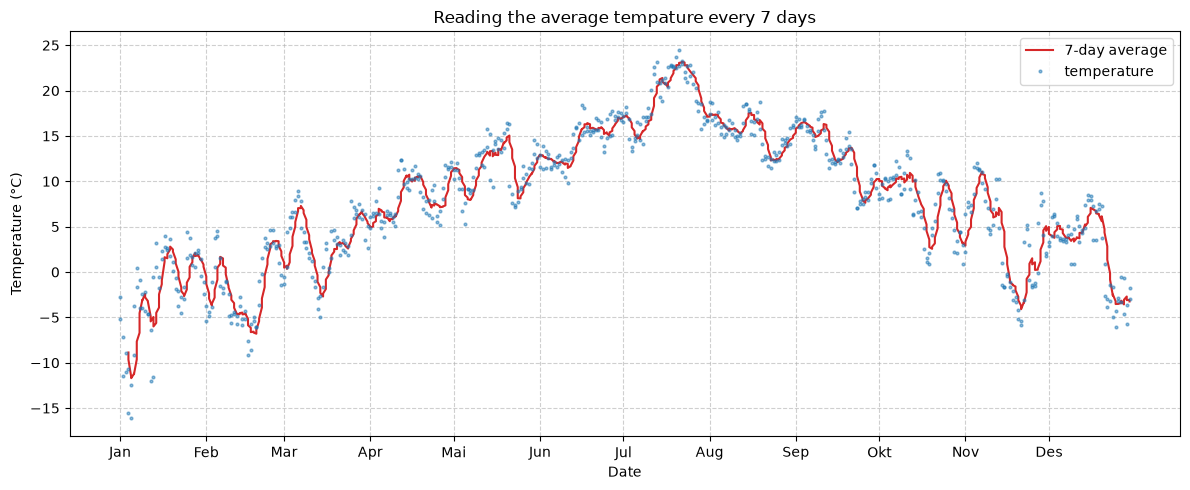

In [ ]:


def dmat(df):
    df_results = df.copy()
    df_results["referenceTime"] = pd.to_datetime(df_results["referenceTime"])
    df_results = df_results.sort_values("referenceTime")

    df_results["7dmat"] = df_results["value"].rolling(window=7).mean()

    return df_results

df_results = dmat(df)


plt.figure(figsize=(12, 5))

plt.plot(
    df_results["referenceTime"], 
    df_results["7dmat"], 
    color="tab:red", 
    label="7-day average")

plt.plot(
    df["date"], 
    df["value"], 
    color="tab:blue", 
    label="temperature",
    linestyle="none", 
    marker="o",
    markersize=2,
    alpha=0.5
)

plt.xticks(ticks=months, labels=month_names)
plt.title("Reading the average tempature every 7 days")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## Sources list:

Temperature data and some code are derived from the Norwegian Meteorological Institute[^1].

[^1]: Meteorologisk institutt. (2025). *Frost API*. Derived from https://frost.met.no

<br>


**Google.** (2026). *Gemini* [Large language model]. https://gemini.google.com

### Declaration on the Use of Generative AI
In this project, generative AI (Gemini) was used as a learning and troubleshooting assistant for:
* Debugging HTTP GET requests and parameter handling for the Frost MET API.
* Implementing the 7-day moving average using `pandas.Series.rolling()`.
* Formatting Matplotlib plots (custom x-axis month ticks and visual styling).

All generated code was reviewed, tested, and integrated by the authors.